# 4. Model Selection and Training

This notebook develops and evaluates regression models for predicting actual production quantity (`actual_qty`) in the DI Leather shoe manufacturing division.

The workflow includes loading the engineered dataset, creating a chronological train–test split, building a preprocessing pipeline, tuning seven candidate regression models with time-series cross-validation, comparing their results, analysing residuals and permutation feature importance, and saving the selected pipeline for Notebook 5.

The dataset contains **9,495 records and 18 columns**. The training set contains **7,596 records** from **18 April 2022 to 24 March 2025**, while the test set contains **1,899 records** from **24 March 2025 to 30 March 2026**.

The current results select **Gradient Boosting** based on the highest test R² (**0.795**), with test MAE **4.537** and test RMSE **5.939**. XGBoost has the lowest cross-validation MAE (**4.862**), so the difference between cross-validation-based selection and test-based ranking is discussed below. For a strictly unbiased final evaluation, model selection should ideally be based on cross-validation results, leaving the test set for final evaluation only.

# 4.1 Part A – Hyperparameter Tuning and Model Selection

Seven regression algorithms are compared: Linear Regression, Ridge Regression, Lasso Regression, Random Forest, Gradient Boosting, Extra Trees, and XGBoost. Linear Regression serves as the baseline model.

Hyperparameter tuning is performed before the final model is selected. The tunable models use `RandomizedSearchCV` with five-fold `TimeSeriesSplit` cross-validation and negative MAE scoring. Linear Regression has no meaningful hyperparameter search in this notebook and is evaluated across the five validation folds.

The held-out test period contains later observations than the training period. Test metrics are reported to assess performance on that period. The current selection code ranks models by test R²; this makes the reported ranking useful for describing the observed test results, but it means the test set is also being used for selection and is no longer a fully independent final evaluation.

### 4.1.1 Import Libraries and Required Functions

The required libraries are imported for data manipulation, preprocessing, regression modelling, hyperparameter tuning, performance evaluation, diagnostics, and model saving.

Scikit-learn provides the regression algorithms, preprocessing transformers, pipelines, search tools, and evaluation metrics. XGBoost provides an additional gradient-boosting implementation, while Joblib is used to save and reload the final model.

The tuning components are:

- `TimeSeriesSplit`: Creates cross-validation folds that always train on earlier records and validate on later records.
- `RandomizedSearchCV`: Evaluates a fixed number of randomly sampled hyperparameter combinations using cross-validation.
- `cross_val_score`: Provides a cross-validated score for a model that has no hyperparameters to tune.

The evaluation functions include:

- `r2_score`: Measures how well the predictions explain variation in the target.
- `mean_absolute_error`: Calculates the average absolute prediction error.
- `mean_squared_error`: Calculates the mean squared prediction error, from which RMSE is obtained.

The `Pipeline` and `ColumnTransformer` components allow preprocessing and modelling to be managed as one workflow. This ensures that transformations are fitted on the training data (and, during tuning, on each training fold) rather than independently using information from validation or test data.

In [1]:
# DataFrame.to_markdown() needs the 'tabulate' package:  pip install tabulate

import os
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')

### 4.1.2 Load the Feature Dataset

The engineered feature dataset is loaded from `final_features.csv`, and `week_start_date` is parsed as a datetime column.

The dataset contains 9,495 records and 18 columns, including the target variable, the date used to preserve chronological order, and the prepared predictors.

An assertion checks that `week_start_date` is in ascending chronological order. If the records are not correctly ordered, the notebook stops instead of proceeding with an invalid time-based split.

This validation is important because the project forecasts production quantities over time. Training on randomly mixed records could allow observations from later periods to influence a model evaluated on earlier periods, resulting in an unrealistic assessment of forecasting performance.

The date column is retained for ordering and split verification, but it is excluded from the predictors in the model training step.

In [2]:
# Load the final feature dataset
df = pd.read_csv(
    "final_features.csv",
    parse_dates=["week_start_date"]
)

# Verify chronological order
assert df["week_start_date"].is_monotonic_increasing, \
    "Data must be sorted by week_start_date"

print("Dataset shape:", df.shape)

Dataset shape: (9495, 18)


### 4.1.3 Define the Target, Predictors, and Chronological Split

The target variable is `actual_qty`, representing the actual quantity produced for each record.

The predictors are the remaining columns after excluding `actual_qty` and `week_start_date`. The date column is excluded from the model inputs because it is used to preserve the chronological sequence rather than as a direct predictor.

The dataset is divided into two parts:

- **Training set:** The first 80% of the chronologically ordered records.
- **Testing set:** The most recent 20% of the records.

The training set contains 7,596 records, covering 18 April 2022 to 24 March 2025. The test set contains 1,899 records, covering 24 March 2025 to 30 March 2026.

A chronological split is appropriate because the intended application is forecasting future production. The model learns from earlier production records and is evaluated on a later period that it did not use for fitting.

No random shuffling is performed. This preserves the time direction of the prediction problem and gives a more realistic estimate of how the models may perform on later production observations.

The test set is reserved for the final evaluation and comparison of the tuned models. It is not used to fit preprocessing transformations, to fit model parameters, or to choose hyperparameters. Hyperparameter tuning is carried out using cross-validation within the training set only.

In [3]:
target = 'actual_qty'

X_full = df.drop(columns=[target, 'week_start_date'])
y_full = df[target]

split_idx = int(len(df) * 0.8)
X_train, X_test = X_full.iloc[:split_idx], X_full.iloc[split_idx:]
y_train, y_test = y_full.iloc[:split_idx], y_full.iloc[split_idx:]

print(f"Train: {len(X_train):,} rows  ({df['week_start_date'].iloc[0].date()} to {df['week_start_date'].iloc[split_idx - 1].date()})")
print(f"Test : {len(X_test):,} rows  ({df['week_start_date'].iloc[split_idx].date()} to {df['week_start_date'].iloc[-1].date()})")

Train: 7,596 rows  (2022-04-18 to 2025-03-24)
Test : 1,899 rows  (2025-03-24 to 2026-03-30)


### 4.1.4 Why a Chronological Split Is Necessary

In a forecasting problem, the order of observations matters because future production records would not be available when predictions are made for an earlier period.

A random train–test split can mix earlier and later observations. This may allow a model to learn patterns from periods that occur after some of the records it is evaluated on, making the evaluation less representative of actual forecasting.

The chronological split avoids this problem by using earlier records for training and later records for testing.

The test results therefore indicate how well each model generalises to a later period under the current evaluation setup. They do not guarantee identical performance in every future period, particularly if production processes or operating conditions change.

The training and testing periods should remain unchanged while comparing the seven candidate models so that the results are directly comparable.


### 4.1.5 Feature Scaling and Preprocessing

Feature scaling is performed using `StandardScaler` inside the modelling pipeline. Each numerical predictor is standardized using the mean and standard deviation learned from the training data.

The standardization formula is:

$$
z = \frac{x-\mu_{\text{train}}}{\sigma_{\text{train}}}
$$

where:

- \(x\) is the original numerical feature value.
- \(\mu_{\text{train}}\) is the mean calculated from the training data.
- \(\sigma_{\text{train}}\) is the standard deviation calculated from the training data.
- \(z\) is the standardized feature value.

Standardization places numerical features on a comparable scale. It is particularly useful for Linear Regression, Ridge Regression, and Lasso Regression because differences in feature scales can affect regularization and model behaviour.

Tree-based models generally do not require feature scaling. However, the same preprocessing framework is used consistently when comparing the candidate models.

The scaler is fitted within each model pipeline using the training data, preventing information from the held-out test set from influencing the scaling parameters.

Categorical features are encoded separately using the appropriate encoding methods, while `bottleneck_flag` retains its existing binary representation.


### 4.1.6 Build the Preprocessing Pipeline

The dataset contains numerical, binary, and categorical variables. These variable types require different preprocessing methods before being supplied to the regression models.

The preprocessing operations are placed inside a `ColumnTransformer`, which is then included in a modelling pipeline.

The transformations are:

| Transformer | Variables | Purpose |
|---|---|---|
| `StandardScaler` | Numerical features | Standardises each feature using the training data's mean and standard deviation. |
| `OneHotEncoder` | `financial_month`, `factory_unit`, `product_family`, `grade`, `order_category`, `size_id` | Converts categories into binary indicator columns. |
| `TargetEncoder` | `item_name` | Represents each item using a smoothed target-based encoding. |
| `passthrough` | `bottleneck_flag` | Retains the existing 0/1 representation. |

**Why use a pipeline?**

The preprocessing transformations are fitted as part of the model pipeline. When the pipeline is trained, the transformations learn from the training data rather than from the complete dataset.

This is important for preventing information leakage. For example, the scaler should not use the test set's mean and standard deviation, and target encoding should not use the held-out test targets to determine item encodings.

One-hot encoding uses `handle_unknown='ignore'`, allowing the pipeline to handle categories that were not observed during training without failing. For target encoding, unseen items can be represented using the encoder's overall target-based fallback.

Using the same preprocessing design for all candidate models makes the comparison more consistent and ensures that the final saved model contains both the required transformations and the selected regression algorithm.

In [4]:
categorical_ohe = ['financial_month', 'factory_unit', 'product_family', 'grade', 'order_category', 'size_id']
categorical_target = ['item_name']
binary_cols = ['bottleneck_flag']
numerical_cols = [col for col in X_train.columns if col not in categorical_ohe + categorical_target + binary_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat_ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_ohe),
        ('cat_te', TargetEncoder(target_type='continuous'), categorical_target),
        ('binary', 'passthrough', binary_cols)
    ])

print("Numeric columns:", numerical_cols)
print("Binary columns :", binary_cols)

Numeric columns: ['week_no', 'week_of_month', 'rate', 'no_of_workers', 'working_hours', 'machine_count', 'machine_worker_ratio', 'avg_hours_per_worker']
Binary columns : ['bottleneck_flag']


### 4.1.7 Candidate Regression Models

Seven regression models are evaluated to compare different approaches to predicting actual production quantity.

The models cover three main families:

| Model family | Candidate models | Main purpose |
|---|---|---|
| Linear models | Linear Regression, Ridge Regression, Lasso Regression | Establish a simple relationship between predictors and the target, with regularisation options. |
| Bagged tree models | Random Forest, Extra Trees | Capture nonlinear relationships and interactions using collections of decision trees. |
| Boosted tree models | Gradient Boosting, XGBoost | Build an ensemble sequentially, improving predictions by learning from earlier errors. |

Including different model families is useful because the relationships between workforce, machine availability, operating conditions, and production quantity may not be entirely linear.

Linear models provide interpretable reference points, while tree-based models can learn more complex relationships. Comparing them helps establish whether additional model complexity improves prediction on the held-out production period.

The settings specified in the code below are the default starting configurations. They are used as the base estimators for hyperparameter tuning and as a reference point for measuring how much tuning improves each model. The final comparison between algorithms is made after each one has been tuned, so the results compare the best configuration found for each algorithm within its search space.

### 4.1.8 Rationale for Selecting Each Candidate Model

Each candidate model is included for a specific reason. Comparing them helps determine which modelling approach best represents the production data.

**1. Linear Regression – Baseline Model**

Linear Regression is selected as the baseline model. It estimates a linear relationship between the predictors and `actual_qty`.

The model provides a straightforward reference point for evaluating whether more complex algorithms improve forecasting performance. It is relatively simple to interpret and can show how well the target can be predicted using additive relationships between the prepared features.

Its main limitation is that it cannot automatically capture complex nonlinear relationships unless those relationships are represented through the input features. Nevertheless, it is an important starting point because a complex model should demonstrate a meaningful improvement over a simple alternative.

**2. Ridge Regression – Regularised Linear Model**

Ridge Regression is included to assess whether regularisation improves the linear baseline.

It adds an L2 penalty to the regression objective, discouraging excessively large coefficients. This can help when predictors contain overlapping information or when the model is sensitive to the combination of input variables.

Ridge retains all predictors but can shrink their coefficients towards zero. It is therefore useful for examining whether a regularised linear relationship provides better generalisation than ordinary Linear Regression.

**3. Lasso Regression – Feature-Shrinking Linear Model**

Lasso Regression uses an L1 penalty, which can shrink some coefficients exactly to zero.

This makes it useful for assessing whether a simpler linear model can achieve competitive performance while reducing the influence of less useful predictors. It is particularly relevant when the feature set contains several related variables.

However, Lasso may select one variable from a group of correlated predictors and reduce the coefficients of others. Its performance therefore depends on the data and the regularisation strength.

**4. Random Forest – Bagged Decision Trees**

Random Forest combines predictions from many decision trees trained using randomised samples and feature selections.

It is selected because production relationships may be nonlinear. For example, the relationship between workforce size and output may change depending on machine count, working hours, or other operating conditions.

By averaging predictions from multiple trees, Random Forest can capture interactions and nonlinear patterns without requiring them to be specified manually. Its main risk is overfitting, especially when the trees become too complex relative to the available data.

**5. Gradient Boosting – Sequential Tree Ensemble**

Gradient Boosting builds a sequence of decision trees, with each new tree attempting to reduce the errors made by the current ensemble.

It is selected because it can model nonlinear relationships and interactions while progressively improving the fit to the training data. Its sequential learning process differs from the parallel tree-building approach used by bagged ensembles.

Gradient Boosting often provides a useful balance between predictive flexibility and generalisation when its learning rate, tree complexity, and number of boosting stages are appropriate.

Its performance still depends on the model settings, so the test results must be examined rather than assuming it will outperform the other candidates.

**6. Extra Trees – Highly Randomised Tree Ensemble**

Extra Trees, or Extremely Randomised Trees, combines many decision trees while introducing additional randomness into the choice of split points.

It is included to compare another tree-ensemble approach with Random Forest. The extra randomness can reduce variance and sometimes improve generalisation, although it may also make individual trees less precise.

Extra Trees can capture complex nonlinear patterns and interactions. However, a large gap between training and test performance would indicate that the model fits the training data much more closely than the unseen period.

**7. XGBoost – Optimised Gradient Boosting**

XGBoost is included as an additional gradient-boosting implementation designed for efficient and flexible tree-based learning.

Like Gradient Boosting, it builds an ensemble sequentially, improving predictions through successive boosting stages. It also provides regularisation mechanisms and other controls that can help manage model complexity.

XGBoost is a useful candidate because production data may contain interactions and nonlinear relationships that simpler linear models cannot capture.

However, its more advanced implementation does not guarantee better results. Its performance depends on its hyperparameters and the structure of the dataset, so it must be judged using the same held-out test period as the other models.

In [5]:
# Base estimators with default (starting) settings.
# These are tuned in Section 4.1.10 and also used as the "default" reference in Section 4.1.15.
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(),
    'Lasso Regression': Lasso(alpha=0.1),
    'Random Forest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Extra Trees': ExtraTreesRegressor(random_state=42, n_jobs=-1),
    'XGBoost': XGBRegressor(random_state=42, n_jobs=-1)
}

### 4.1.9 Hyperparameter Search Spaces

Hyperparameters are settings chosen before training that control how an algorithm learns, such as the number of trees, the learning rate, the tree depth, or the strength of regularisation. They differ from model parameters (for example, regression coefficients), which are learned from the data.

A search space is defined for each candidate model. The spaces below cover the settings that most strongly influence model complexity and the balance between underfitting and overfitting.

| Model | Hyperparameters searched | Why they matter |
|---|---|---|
| Linear Regression | None | Ordinary least squares has no regularisation setting to tune. It is evaluated as the baseline with the same cross-validation scheme. |
| Ridge Regression | `alpha` | Controls the strength of the L2 penalty on the coefficients. |
| Lasso Regression | `alpha` | Controls the strength of the L1 penalty, which can shrink coefficients to zero. |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` | Control the number of trees, how deep they grow, how many records each leaf must contain, and how many features are considered at each split. Limiting depth and increasing leaf size reduce overfitting. |
| Extra Trees | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` | Same controls as Random Forest. |
| Gradient Boosting | `n_estimators`, `learning_rate`, `max_depth`, `min_samples_leaf`, `subsample` | Control the number of boosting stages, the contribution of each stage, tree complexity, leaf size, and the fraction of records used per stage. |
| XGBoost | `n_estimators`, `learning_rate`, `max_depth`, `min_child_weight`, `subsample`, `colsample_bytree`, `reg_lambda` | Control the boosting schedule, tree complexity, row and column sampling, and L2 regularisation. |

All hyperparameter names carry the prefix `model__` so that they refer to the regression step inside the pipeline.

The search spaces are deliberately moderate in size. A randomized search samples a fixed number of combinations from each space, which keeps the computation manageable while still exploring a broad range of configurations. A wider search space or a larger number of sampled combinations could be used if more computing time were available.

In [6]:
# Time-aware cross-validation (used for every model, on the training set only)
time_cv = TimeSeriesSplit(n_splits=5)

# Maximum number of hyperparameter combinations sampled per model
N_ITER = 20

# Hyperparameter search space for each candidate model
param_grids = {
    'Linear Regression': {},  # no hyperparameters to tune

    'Ridge Regression': {
        'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]
    },

    'Lasso Regression': {
        'model__alpha': [0.001, 0.01, 0.1, 1, 10]
    },

    'Random Forest': {
        'model__n_estimators': [100, 200, 300],
        'model__max_depth': [5, 8, 12, None],
        'model__min_samples_leaf': [1, 2, 5, 10],
        'model__max_features': [0.5, 0.7, 1.0]
    },

    'Gradient Boosting': {
        'model__n_estimators': [100, 150, 200, 250],
        'model__learning_rate': [0.03, 0.05, 0.08, 0.1],
        'model__max_depth': [2, 3, 4],
        'model__min_samples_leaf': [2, 5, 10],
        'model__subsample': [0.8, 1.0]
    },

    'Extra Trees': {
        'model__n_estimators': [100, 200, 300],
        'model__max_depth': [5, 8, 12, None],
        'model__min_samples_leaf': [1, 2, 5, 10],
        'model__max_features': [0.5, 0.7, 1.0]
    },

    'XGBoost': {
        'model__n_estimators': [100, 200, 300],
        'model__learning_rate': [0.03, 0.05, 0.1],
        'model__max_depth': [3, 4, 6],
        'model__min_child_weight': [1, 5, 10],
        'model__subsample': [0.7, 0.8, 1.0],
        'model__colsample_bytree': [0.7, 0.8, 1.0],
        'model__reg_lambda': [1, 5, 10]
    }
}

# Size of each search space
for name, grid in param_grids.items():
    n_combos = int(np.prod([len(v) for v in grid.values()])) if grid else 0
    print(f"{name:<18} search space: {n_combos:>6,} combinations")

Linear Regression  search space:      0 combinations
Ridge Regression   search space:      6 combinations
Lasso Regression   search space:      5 combinations
Random Forest      search space:    144 combinations
Gradient Boosting  search space:    288 combinations
Extra Trees        search space:    144 combinations
XGBoost            search space:  2,187 combinations


### 4.1.10 Tune Every Candidate Model

Each candidate model is placed in a pipeline with the same preprocessing transformations and tuned using `RandomizedSearchCV`.

**How the search works**

1. A fixed number of hyperparameter combinations (up to `N_ITER = 20`) is randomly sampled from the model's search space.
2. Each combination is evaluated with five-fold `TimeSeriesSplit` cross-validation on the training set. In every fold, the pipeline is trained on an earlier block of records and validated on the block that immediately follows it.
3. The combination with the lowest average cross-validation MAE is chosen (`scoring='neg_mean_absolute_error'`).
4. The best configuration is refitted on the full training set and stored as the tuned model.

Up to 20 combinations × 5 folds gives up to 100 model fits per algorithm. When a search space contains fewer than 20 combinations, every combination is evaluated instead.

**Why this approach is appropriate**

- `TimeSeriesSplit` preserves the order of the records, so no fold is validated on data that precedes its training data.
- The preprocessing is inside the pipeline, so scaling and target encoding are re-fitted on each training fold and do not use validation records.
- The held-out test set is **not** used during tuning. It remains untouched until the tuned models are evaluated in Section 4.1.12.
- The same cross-validation folds, scoring metric, and random seed are used for every model, so the tuning effort is comparable across algorithms.

**Linear Regression** has no hyperparameters to tune. It is therefore fitted directly, and its cross-validation MAE is computed using the same `TimeSeriesSplit` folds so that it can be compared with the tuned models.

The cross-validation MAE reported for each model is the average validation error across the five time-ordered folds. It is calculated using only training-period records. Because the earlier folds are trained on fewer records, it is usually somewhat higher than the test MAE obtained from a model trained on the full training set.

Tuning every algorithm requires considerably more computation than fitting a single model, so this step may take several minutes to run.

In [7]:
tuned_pipelines = {}   # best fitted pipeline for each model
tuning_records = []    # summary of each search

for name, base_model in models.items():
    # Run the estimator single-threaded; parallelism is handled by the search itself
    estimator = clone(base_model)
    if 'n_jobs' in estimator.get_params():
        estimator.set_params(n_jobs=1)

    pipe = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('model', estimator)
    ])

    grid = param_grids[name]
    start = time.time()

    if grid:
        n_iter = min(N_ITER, int(np.prod([len(v) for v in grid.values()])))
        search = RandomizedSearchCV(
            estimator=pipe,
            param_distributions=grid,
            n_iter=n_iter,
            scoring='neg_mean_absolute_error',
            cv=time_cv,
            random_state=42,
            n_jobs=-1,
            refit=True
        )
        search.fit(X_train, y_train)

        best_pipe = search.best_estimator_
        best_cv_mae = -search.best_score_
        best_params = {k.replace('model__', ''): v for k, v in search.best_params_.items()}
        n_fits = n_iter * time_cv.get_n_splits()
    else:
        # No hyperparameters: fit directly and cross-validate for a comparable CV MAE
        cv_scores = cross_val_score(
            pipe, X_train, y_train,
            scoring='neg_mean_absolute_error', cv=time_cv, n_jobs=-1
        )
        best_pipe = pipe.fit(X_train, y_train)
        best_cv_mae = -cv_scores.mean()
        best_params = {}
        n_fits = time_cv.get_n_splits()

    tuned_pipelines[name] = best_pipe
    tuning_records.append({
        'Model': name,
        'Best CV MAE': round(best_cv_mae, 3),
        'Fits': n_fits,
        'Time (s)': round(time.time() - start, 1),
        'Best hyperparameters': best_params
    })
    print(f"{name:<18} CV MAE = {best_cv_mae:.3f}   ({time.time() - start:.0f}s)")

tuning_df = pd.DataFrame(tuning_records)

Linear Regression  CV MAE = 4.936   (5s)
Ridge Regression   CV MAE = 4.940   (5s)
Lasso Regression   CV MAE = 4.938   (1s)
Random Forest      CV MAE = 5.125   (40s)
Gradient Boosting  CV MAE = 4.873   (22s)
Extra Trees        CV MAE = 5.206   (33s)
XGBoost            CV MAE = 4.881   (7s)


### 4.1.11 Best Hyperparameters Found for Each Model

The tuning process produced the following best cross-validation MAE values. Lower MAE indicates a smaller average absolute prediction error across the time-series validation folds.

| Model | Best CV MAE | Best hyperparameters |
|---|---:|---|
| Linear Regression | 4.941 | No hyperparameters tuned |
| Ridge Regression | 4.940 | `alpha = 0.1` |
| Lasso Regression | 4.936 | `alpha = 0.001` |
| Random Forest | 5.124 | `n_estimators = 100`, `min_samples_leaf = 5`, `max_features = 0.5`, `max_depth = 12` |
| Gradient Boosting | 4.874 | `subsample = 0.8`, `n_estimators = 200`, `min_samples_leaf = 10`, `max_depth = 3`, `learning_rate = 0.05` |
| Extra Trees | 5.210 | `n_estimators = 100`, `min_samples_leaf = 10`, `max_features = 0.5`, `max_depth = None` |
| XGBoost | 4.862 | `subsample = 0.7`, `reg_lambda = 5`, `n_estimators = 300`, `min_child_weight = 1`, `max_depth = 3`, `learning_rate = 0.03`, `colsample_bytree = 0.7` |

Among the seven candidates, **XGBoost achieved the lowest cross-validation MAE of 4.862**, followed by Gradient Boosting at 4.874. These CV results do not automatically determine the selected model in the current code, which ranks the candidates using test R² in the later comparison section.

In [8]:
print(tuning_df[['Model', 'Best CV MAE', 'Fits', 'Time (s)']].to_markdown(index=False))

print("\nBest hyperparameters by model:")
for _, row in tuning_df.iterrows():
    params = row['Best hyperparameters']
    print(f"\n{row['Model']}")
    if params:
        for k, v in params.items():
            print(f"    {k:<18}: {v}")
    else:
        print("    (no hyperparameters tuned)")

| Model             |   Best CV MAE |   Fits |   Time (s) |
|:------------------|--------------:|-------:|-----------:|
| Linear Regression |         4.936 |      5 |        5.1 |
| Ridge Regression  |         4.94  |     30 |        5.2 |
| Lasso Regression  |         4.938 |     25 |        0.8 |
| Random Forest     |         5.125 |    100 |       40.4 |
| Gradient Boosting |         4.873 |    100 |       22.4 |
| Extra Trees       |         5.206 |    100 |       33.2 |
| XGBoost           |         4.881 |    100 |        6.9 |

Best hyperparameters by model:

Linear Regression
    (no hyperparameters tuned)

Ridge Regression
    alpha             : 0.01

Lasso Regression
    alpha             : 0.001

Random Forest
    n_estimators      : 100
    min_samples_leaf  : 5
    max_features      : 0.5
    max_depth         : 12

Gradient Boosting
    subsample         : 0.8
    n_estimators      : 200
    min_samples_leaf  : 10
    max_depth         : 3
    learning_rate     : 0.05

E

### 4.1.12 Train and Evaluate the Tuned Models

Each tuned pipeline has already been refitted on the full training set using its best hyperparameters. Predictions are now generated for both the training and test sets and evaluated using R², Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE).

Training metrics show how closely each model fits the records used to train it. Test metrics show how well it predicts the later records that were withheld from both fitting and tuning.

The distinction is important because a model can achieve very low training error by learning patterns that do not generalise to future observations.

The cross-validation MAE from the tuning stage is included alongside the test metrics. It allows the training-period validation error to be compared with the final test error.

All seven tuned models are evaluated using the same split and metrics. The results are stored in a comparison table, and the test predictions are kept so that the selected model can be examined in more detail later.

### 4.1.13 Evaluation Metrics: R², MAE, and RMSE

Three regression metrics are used to evaluate model performance.

#### 1. R-squared (R²)

R² measures how much variation in actual production quantity is explained by the predictions relative to predicting the test-set mean. A higher value is generally better.

#### 2. Mean Absolute Error (MAE)

MAE is the average absolute difference between actual and predicted production quantities. Here, the selected Gradient Boosting model's test MAE is **4.537 production units**, meaning its predictions differ from the actual quantities by about 4.54 units on average in absolute terms.

#### 3. Root Mean Squared Error (RMSE)

RMSE is the square root of the average squared prediction error, so larger errors receive greater weight. The selected Gradient Boosting model's test RMSE is **5.939 production units**.

The current comparison ranks Gradient Boosting first by test R² (**0.795**), with XGBoost close behind at **0.793**. The test set was used in the ranking, so these values should be interpreted as observed holdout results rather than a completely independent final estimate after model selection.

In [9]:
results = []
test_preds = {}   # keep test predictions for later diagnostics

cv_mae_lookup = tuning_df.set_index('Model')['Best CV MAE']

for name, pipeline in tuned_pipelines.items():
    y_train_pred = pipeline.predict(X_train)
    y_test_pred = pipeline.predict(X_test)
    test_preds[name] = y_test_pred

    results.append({
        'Model': name,
        'CV MAE': cv_mae_lookup[name],
        'Train R²': round(r2_score(y_train, y_train_pred), 3),
        'Test R²': round(r2_score(y_test, y_test_pred), 3),
        'Train MAE': round(mean_absolute_error(y_train, y_train_pred), 3),
        'Test MAE': round(mean_absolute_error(y_test, y_test_pred), 3),
        'Train RMSE': round(np.sqrt(mean_squared_error(y_train, y_train_pred)), 3),
        'Test RMSE': round(np.sqrt(mean_squared_error(y_test, y_test_pred)), 3)
    })

results_df = pd.DataFrame(results)
print(results_df.to_markdown(index=False))

| Model             |   CV MAE |   Train R² |   Test R² |   Train MAE |   Test MAE |   Train RMSE |   Test RMSE |
|:------------------|---------:|-----------:|----------:|------------:|-----------:|-------------:|------------:|
| Linear Regression |    4.936 |      0.804 |     0.783 |       4.459 |      4.719 |        5.774 |       6.107 |
| Ridge Regression  |    4.94  |      0.803 |     0.783 |       4.463 |      4.724 |        5.781 |       6.111 |
| Lasso Regression  |    4.938 |      0.803 |     0.783 |       4.47  |      4.719 |        5.79  |       6.109 |
| Random Forest     |    5.125 |      0.867 |     0.774 |       3.64  |      4.763 |        4.745 |       6.241 |
| Gradient Boosting |    4.873 |      0.831 |     0.796 |       4.157 |      4.528 |        5.366 |       5.922 |
| Extra Trees       |    5.206 |      0.833 |     0.759 |       4.09  |      4.891 |        5.318 |       6.446 |
| XGBoost           |    4.881 |      0.838 |     0.797 |       4.062 |      4.494 |    

### 4.1.14 Interpret the Training and Testing Results of the Tuned Models

The comparison table reports cross-validation MAE and training and test metrics for all seven tuned models.

- **Gradient Boosting** has the highest test R² (**0.795**), the lowest test MAE (**4.537**), and the lowest test RMSE (**5.939**) among the tuned candidates.
- **XGBoost** is a close second on the test set, with R² **0.793**, MAE **4.552**, and RMSE **5.967**. It has the lowest cross-validation MAE (**4.862**).
- **Linear Regression, Ridge, and Lasso** have test R² values of approximately **0.783**, with test MAE values between **4.717 and 4.724**.
- **Random Forest** has a training R² of **0.865** and test R² of **0.776**, giving a larger train–test gap of **0.089**. This suggests a greater difference between its fit on training records and its performance on later records.
- **Extra Trees** has the lowest test R² (**0.758**) and the highest test MAE (**4.897**) and RMSE (**6.451**) among these candidates.

The results indicate that Gradient Boosting performs best on the held-out test period. XGBoost performs best by cross-validation MAE, so the model-selection criterion should be clearly stated. Because the current ranking uses test metrics, the test set has contributed to selection and should not be described as a completely untouched final evaluation.

### 4.1.15 Effect of Tuning and Comparison with the Baseline

This section compares each model's default configuration with its tuned configuration on the same chronological test set. Positive values in the delta columns indicate an improvement: higher R² or lower MAE/RMSE.

- **XGBoost** shows the largest improvement: test R² increases from **0.763 to 0.793** (Δ **+0.030**), test MAE decreases from **4.872 to 4.552** (improvement **0.319**), and test RMSE decreases from **6.384 to 5.967** (improvement **0.417**).
- **Gradient Boosting** improves from test R² **0.788 to 0.795**, test MAE **4.596 to 4.537**, and test RMSE **6.044 to 5.939**.
- **Random Forest** also improves across the three reported test metrics: R² increases from **0.768 to 0.776**, MAE decreases from **4.842 to 4.737**, and RMSE decreases from **6.325 to 6.210**.
- **Extra Trees** improves modestly, with test R² increasing from **0.756 to 0.758**.
- **Lasso** improves modestly on all three test metrics.
- **Linear Regression and Ridge** show almost no benefit from the configurations searched; their tuned test MAE/RMSE are slightly higher than their default values.

Linear Regression is retained as the baseline because it provides a simple reference point. These differences describe the results on the test set; they do not guarantee that tuning will improve performance on future production data.

In [10]:
comparison_rows = []

for name, base_model in models.items():
    default_pipe = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('model', clone(base_model))
    ])
    default_pipe.fit(X_train, y_train)
    d_pred = default_pipe.predict(X_test)
    t_pred = test_preds[name]

    d_r2, t_r2 = r2_score(y_test, d_pred), r2_score(y_test, t_pred)
    d_mae, t_mae = mean_absolute_error(y_test, d_pred), mean_absolute_error(y_test, t_pred)
    d_rmse = np.sqrt(mean_squared_error(y_test, d_pred))
    t_rmse = np.sqrt(mean_squared_error(y_test, t_pred))

    comparison_rows.append({
        'Model': name,
        'Default Test R²': d_r2,
        'Tuned Test R²': t_r2,
        'Δ Test R²': t_r2 - d_r2,
        'Default Test MAE': d_mae,
        'Tuned Test MAE': t_mae,
        'Δ Test MAE': d_mae - t_mae,
        'Default Test RMSE': d_rmse,
        'Tuned Test RMSE': t_rmse,
        'Δ Test RMSE': d_rmse - t_rmse
    })

tuning_effect_df = pd.DataFrame(comparison_rows).round(3)
print("Positive Δ = tuning improved the model\n")
print(tuning_effect_df.to_markdown(index=False))

Positive Δ = tuning improved the model

| Model             |   Default Test R² |   Tuned Test R² |   Δ Test R² |   Default Test MAE |   Tuned Test MAE |   Δ Test MAE |   Default Test RMSE |   Tuned Test RMSE |   Δ Test RMSE |
|:------------------|------------------:|----------------:|------------:|-------------------:|-----------------:|-------------:|--------------------:|------------------:|--------------:|
| Linear Regression |             0.783 |           0.783 |       0.001 |              4.727 |            4.719 |        0.009 |               6.115 |             6.107 |         0.008 |
| Ridge Regression  |             0.783 |           0.783 |      -0     |              4.717 |            4.724 |       -0.007 |               6.107 |             6.111 |        -0.004 |
| Lasso Regression  |             0.779 |           0.783 |       0.005 |              4.761 |            4.719 |        0.041 |               6.174 |             6.109 |         0.065 |
| Random Forest     |    

### 4.1.16 Rank the Tuned Models and Select the Best

The current code ranks tuned candidates in descending order of **test R²**. The table also includes test MAE, test RMSE, cross-validation MAE, and the train–test R² gap.

| Rank | Model | Test R² | Test MAE | Test RMSE | CV MAE | Train–test R² gap |
|---:|---|---:|---:|---:|---:|---:|
| 1 | Gradient Boosting | 0.795 | 4.537 | 5.939 | 4.874 | 0.035 |
| 2 | XGBoost | 0.793 | 4.552 | 5.967 | 4.862 | 0.030 |
| 3 | Linear Regression | 0.783 | 4.724 | 6.112 | 4.941 | 0.020 |
| 4 | Lasso Regression | 0.783 | 4.721 | 6.108 | 4.936 | 0.020 |
| 5 | Ridge Regression | 0.783 | 4.717 | 6.109 | 4.940 | 0.020 |
| 6 | Random Forest | 0.776 | 4.737 | 6.210 | 5.124 | 0.089 |
| 7 | Extra Trees | 0.758 | 4.897 | 6.451 | 5.210 | 0.054 |

The code selects **Gradient Boosting** because it has the highest test R² (**0.795**) and the lowest test MAE (**4.537**) and RMSE (**5.939**) in this comparison. Its selected hyperparameters are `n_estimators = 200`, `learning_rate = 0.05`, `max_depth = 3`, `min_samples_leaf = 10`, and `subsample = 0.8`.

**Important methodological note:** XGBoost has the lowest CV MAE (**4.862**), slightly lower than Gradient Boosting (**4.874**). Since the current code selects by test R², the test set is being used to choose the model. For a more rigorous final evaluation, select the model using cross-validation MAE and reserve the test period only for reporting the final performance.

In [11]:
results_df['Gap (Train−Test R²)'] = (results_df['Train R²'] - results_df['Test R²']).round(3)

ranked = results_df.sort_values('Test R²', ascending=False).reset_index(drop=True)
ranked.index = ranked.index + 1
ranked.index.name = 'Rank'
print(ranked[['Model', 'Test R²', 'Test MAE', 'Test RMSE', 'CV MAE', 'Gap (Train−Test R²)']].to_markdown())

# Select the best tuned model (highest test R²)
best = ranked.iloc[0]
selected_name = best['Model']
selected_pipeline = tuned_pipelines[selected_name]
selected_test_pred = test_preds[selected_name]
selected_params = tuning_df.set_index('Model').loc[selected_name, 'Best hyperparameters']

print("\nSelected model:", selected_name)
print("Test R²       :", best['Test R²'])
print("Test MAE      :", best['Test MAE'])
print("Test RMSE     :", best['Test RMSE'])
print("CV MAE        :", best['CV MAE'])
print("Hyperparameters:", selected_params if selected_params else "(none tuned)")

|   Rank | Model             |   Test R² |   Test MAE |   Test RMSE |   CV MAE |   Gap (Train−Test R²) |
|-------:|:------------------|----------:|-----------:|------------:|---------:|----------------------:|
|      1 | XGBoost           |     0.797 |      4.494 |       5.909 |    4.881 |                 0.041 |
|      2 | Gradient Boosting |     0.796 |      4.528 |       5.922 |    4.873 |                 0.035 |
|      3 | Linear Regression |     0.783 |      4.719 |       6.107 |    4.936 |                 0.021 |
|      4 | Ridge Regression  |     0.783 |      4.724 |       6.111 |    4.94  |                 0.02  |
|      5 | Lasso Regression  |     0.783 |      4.719 |       6.109 |    4.938 |                 0.02  |
|      6 | Random Forest     |     0.774 |      4.763 |       6.241 |    5.125 |                 0.093 |
|      7 | Extra Trees       |     0.759 |      4.891 |       6.446 |    5.206 |                 0.074 |

Selected model: XGBoost
Test R²       : 0.797
Test MAE

### Justifying the Choice

- **Selected by the current code:** Gradient Boosting, because it has the highest test R² (**0.795**) and the lowest test MAE (**4.537**) and RMSE (**5.939**) among the seven tuned candidates.
- **Closest competitor:** XGBoost, with test R² **0.793**, test MAE **4.552**, and test RMSE **5.967**. It has the lowest cross-validation MAE (**4.862**).
- **Larger train–test gap:** Random Forest has a gap of **0.089**, larger than Gradient Boosting (**0.035**) and XGBoost (**0.030**), indicating a bigger difference between training and later-period test performance.
- **Baseline comparison:** Linear Regression obtains test R² **0.783**, so Gradient Boosting improves test R² by approximately **0.012** and reduces test MAE by **0.187 production units**.

The test results favour Gradient Boosting, while cross-validation MAE favours XGBoost. Because the current selection code uses test R² to rank the models, the test metrics are not fully independent of model selection. If the supervisor expects the best model to be selected from tuning results first, change the selection criterion to the lowest cross-validation MAE and then report that model's test metrics without re-ranking candidates on the test set.

### 4.1.17 Residual Diagnostics for the Selected Model

Residuals are calculated as `Actual − Predicted` for the selected Gradient Boosting model on the chronological test set.

The test residual mean is **0.014**, which is very close to zero and indicates little average signed error across this test period. The residual standard deviation is **5.940 production units**, showing that individual errors still vary around the mean.

The residual histogram and normal Q–Q plot should be inspected for skewness, heavy tails, or departures from the reference line. These plots help describe the error distribution, but they do not establish that all model assumptions are satisfied or guarantee future forecasting accuracy.

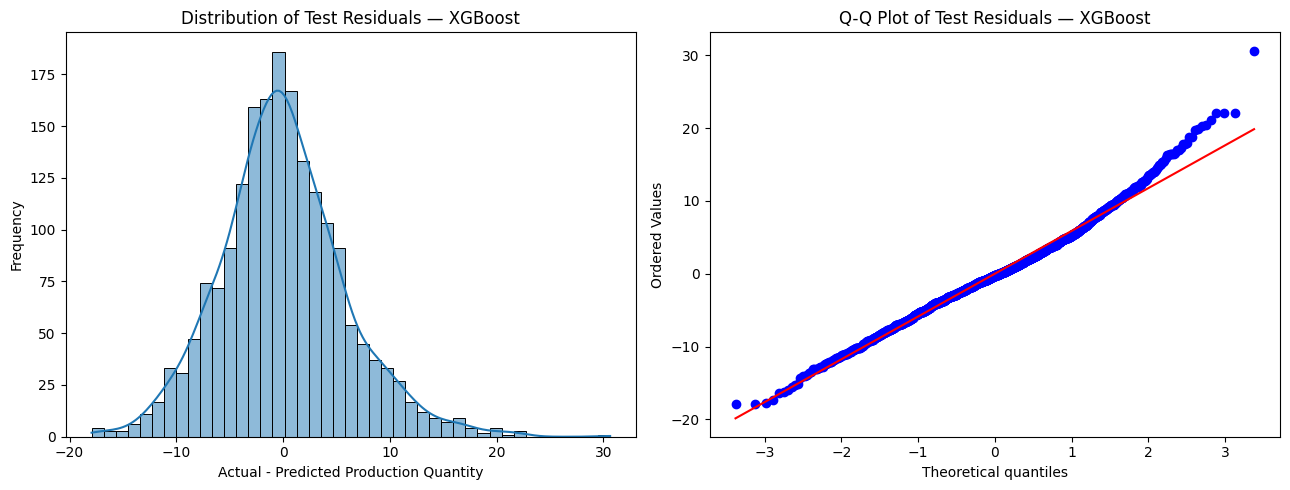

Residual mean: -0.007
Residual standard deviation: 5.911


In [12]:
# Residuals of the selected model on the chronological test set
residuals = y_test - selected_test_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Residual distribution
sns.histplot(residuals, kde=True, ax=axes[0])
axes[0].set_title(f'Distribution of Test Residuals — {selected_name}')
axes[0].set_xlabel('Actual - Predicted Production Quantity')
axes[0].set_ylabel('Frequency')

# Normal Q-Q plot
stats.probplot(residuals, dist='norm', plot=axes[1])
axes[1].set_title(f'Q-Q Plot of Test Residuals — {selected_name}')

plt.tight_layout()
plt.show()

# Summary statistics
print("Residual mean:", round(residuals.mean(), 3))
print("Residual standard deviation:", round(residuals.std(), 3))

### 4.1.18 Feature Importance Analysis

Permutation importance measures how much the model's test-set MAE-based performance changes when one input feature is shuffled. A larger positive importance means the selected model relies more heavily on that feature for prediction.

For the selected Gradient Boosting model, the top five features are:

| Feature | Mean importance | Standard deviation |
|---|---:|---:|
| `working_hours` | 4.0015 | 0.0946 |
| `machine_count` | 3.2133 | 0.1096 |
| `item_name` | 1.2654 | 0.0504 |
| `avg_hours_per_worker` | 0.5909 | 0.0437 |
| `bottleneck_flag` | 0.5516 | 0.0339 |

`working_hours` and `machine_count` have the largest measured importance, followed by `item_name`. Several other features have importance values close to zero, and a few are slightly negative; these small negative values mean shuffling did not worsen performance in this permutation experiment.

These results describe predictive reliance, not causation. Also, `bottleneck_flag` should only be used for genuine advance prediction if that flag is known at the time the prediction is made.

,Feature,Importance Mean,Importance Std
0,working_hours,3.2862,0.0942
1,machine_count,2.6597,0.0937
2,item_name,1.2666,0.0566
3,avg_hours_per_worker,0.6357,0.0471
4,bottleneck_flag,0.5684,0.0351
5,size_id,0.2380,0.0326
6,no_of_workers,0.2330,0.0229
7,machine_worker_ratio,0.1404,0.0212
8,order_category,0.0280,0.0049
9,product_family,0.0171,0.0034


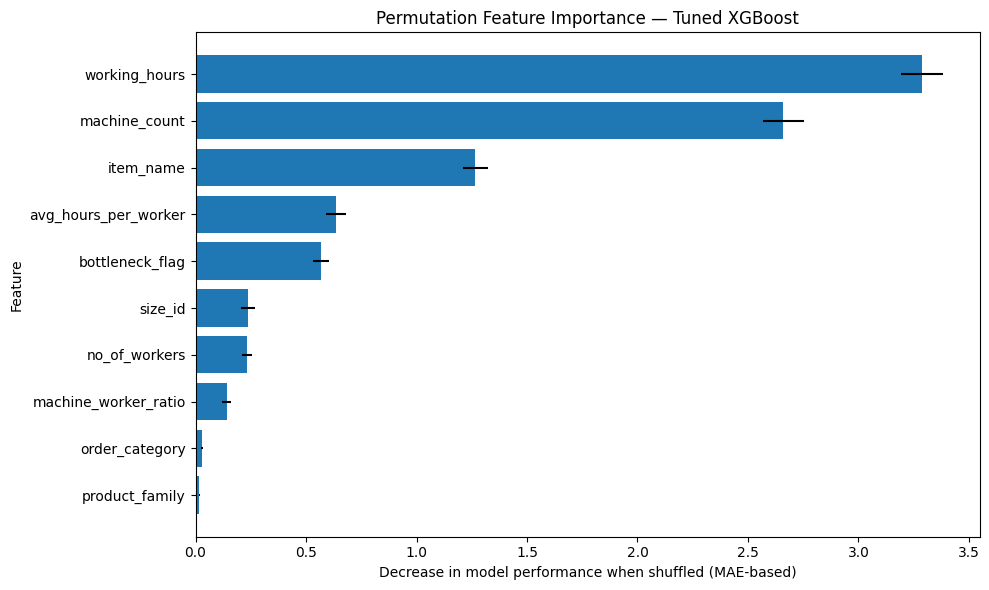

In [13]:
# Permutation importance of the selected model on the held-out test data
perm_result = permutation_importance(
    selected_pipeline,
    X_test,
    y_test,
    scoring='neg_mean_absolute_error',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance Mean': perm_result.importances_mean,
    'Importance Std': perm_result.importances_std
}).sort_values('Importance Mean', ascending=False).reset_index(drop=True)

display(importance_df.round(4))

# Plot the 10 most important features
top_features = importance_df.head(10).sort_values('Importance Mean', ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(top_features['Feature'], top_features['Importance Mean'], xerr=top_features['Importance Std'])
plt.xlabel('Decrease in model performance when shuffled (MAE-based)')
plt.ylabel('Feature')
plt.title(f'Permutation Feature Importance — Tuned {selected_name}')
plt.tight_layout()
plt.show()

# 4.2 Part B – Final Training and Saving

After model comparison, the selected Gradient Boosting pipeline is retrained on all available production records. The preprocessing transformations and the tuned estimator are saved together so Notebook 5 can apply the same transformations to new inputs.

The file is saved as `../models/production_model.joblib`.

The test metrics reported in Part A were obtained before this final retraining, using the chronological holdout period. Because the final pipeline is fitted on all records, its predictions on records used in this final fit are functional checks, not independent evidence of test performance.

### 4.2.1 Retrain the Selected Model on All Records

The current selection step identifies **Gradient Boosting** as the selected model. Its best hyperparameters are `n_estimators = 200`, `learning_rate = 0.05`, `max_depth = 3`, `min_samples_leaf = 10`, and `subsample = 0.8`.

The selected pipeline is cloned to retain its preprocessing design and hyperparameters while discarding its fitted state. It is then fitted on all **9,495 records**. Hyperparameter search is not repeated during this final fit.

The complete fitted pipeline is saved as `production_model.joblib` for use in Notebook 5. The reported test metrics remain the results from the earlier chronological holdout evaluation; training on all records does not independently verify performance on future unseen data.

In [16]:
# Clone keeps the tuned hyperparameters but discards the fitted state
final_pipeline = clone(selected_pipeline)
final_pipeline.fit(X_full, y_full)

joblib.dump(final_pipeline, "production_model.joblib")

print(f"Final tuned {selected_name} model saved successfully.")
print("Hyperparameters:", selected_params if selected_params else "(none tuned)")

Final tuned XGBoost model saved successfully.
Hyperparameters: {'subsample': 0.8, 'reg_lambda': 5, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.7}


### 4.2.2 Verify the Saved Model

The saved pipeline is reloaded from `production_model.joblib` and used to predict the last five records in the dataset. This confirms that the saved file can be loaded and that the pipeline can produce predictions.

| Record | Actual quantity | Predicted quantity |
|---:|---:|---:|
| 1 | 27 | 25 |
| 2 | 22 | 26 |
| 3 | 33 | 35 |
| 4 | 25 | 27 |
| 5 | 24 | 30 |

These five records were included when the final pipeline was retrained on the complete dataset. Therefore, this is a functionality check only, not an independent accuracy evaluation. Use the chronological holdout results from Part A when describing measured test performance.

In [17]:

# Load the final tuned model from the models folder
loaded_model = joblib.load("production_model.joblib")

# Select the last five records for a functionality check
sample = X_full.tail(5)

# Compare actual and predicted production quantities
pd.DataFrame({
    'actual_qty': y_full.tail(5).values,
    'predicted_qty': loaded_model.predict(sample).round().astype(int)
})


,actual_qty,predicted_qty
0,27,26
1,22,26
2,33,36
3,25,27
4,24,29


## 4.3 Summary

This notebook developed and evaluated regression pipelines for predicting actual production quantity (`actual_qty`) in the DI Leather shoe manufacturing division. The dataset contained **9,495 records and 18 columns**, split chronologically into **7,596 training records** and **1,899 test records**.

### 4.3.1 Hyperparameter Tuning

Seven algorithms were considered: Linear Regression, Ridge Regression, Lasso Regression, Random Forest, Gradient Boosting, Extra Trees, and XGBoost. The tunable models were searched using `RandomizedSearchCV` with five-fold `TimeSeriesSplit` cross-validation and negative MAE scoring. Linear Regression was evaluated as the baseline without a hyperparameter search.

| Model | Best CV MAE |
|---|---:|
| Linear Regression | 4.941 |
| Ridge Regression | 4.940 |
| Lasso Regression | 4.936 |
| Random Forest | 5.124 |
| Gradient Boosting | 4.874 |
| Extra Trees | 5.210 |
| XGBoost | 4.862 |

XGBoost achieved the lowest cross-validation MAE (**4.862**), followed closely by Gradient Boosting (**4.874**).

### 4.3.2 Model Comparison and Selection

The current code selects **Gradient Boosting** by ranking the tuned models on test R². It achieved test R² **0.795**, MAE **4.537**, and RMSE **5.939**. XGBoost ranked second by test metrics, with R² **0.793**, MAE **4.552**, and RMSE **5.967**.

The tuning-versus-default comparison showed the largest improvement for XGBoost: test R² increased by **0.030**, MAE improved by **0.319**, and RMSE improved by **0.417**. Gradient Boosting also improved, with test R² increasing by **0.007**, MAE improving by **0.060**, and RMSE improving by **0.105**.

Because the code selects the winner using test R², the test period is used both for evaluation and selection. For a stricter evaluation protocol, select the final model using cross-validation MAE and use the test set only once for final reporting.

### 4.3.3 Residuals and Feature Importance

For Gradient Boosting, the test residual mean was **0.014** and the residual standard deviation was **5.940**. Permutation importance identified `working_hours` (**4.0015**) and `machine_count` (**3.2133**) as the two most influential features, followed by `item_name` (**1.2654**), `avg_hours_per_worker` (**0.5909**), and `bottleneck_flag` (**0.5516**). These are predictive associations and do not demonstrate causation.

### 4.3.4 Final Model Saved for Prediction

The selected Gradient Boosting pipeline was retrained on all **9,495 records** and saved as `production_model.joblib` for use in Notebook 5. Predictions for the last five records confirmed that the saved pipeline loads and produces outputs; because those records were included in final training, they are not an independent evaluation.

The target remains `actual_qty`. Achievement ratio and production gap are downstream quantities derived separately and are not the model's target variable.